# 🏦 Risk Alert Classifier
### Supervised Learning Project | Beginner-friendly walkthrough

**Business story:** A digital bank wants to identify customers who may be at high risk of default or suspicious activity. Missing a genuinely risky customer can be costly, so we will pay close attention to **Recall for the high-risk class** and **false negatives**, not just accuracy.

**Project goal:** Build, compare, and tune classification models while handling an imbalanced dataset.

**How to use this notebook**
1. Keep `Risk_Alert_Classifier_Dataset_4600.csv` in the same folder as this notebook.
2. Run cells from top to bottom.
3. Read the short interpretation after each major output.
4. Before submission, use **Kernel → Restart & Run All** and make sure no cell shows an error.

> ⚠️ This is an educational risk-alert model, not a production banking decision system. Model predictions should be reviewed and validated before any real-world use.

## 🧭 Project roadmap

```text
Load data → Understand target and missing values → Split data
     ↓
Impute missing values → Baseline Logistic Regression
     ↓
Balance training data (Under / Over / SMOTE / ADASYN)
     ↓
Decision Tree + Random Forest → RandomizedSearchCV → GridSearchCV
     ↓
Compare metrics + ROC curves → Select model → Business conclusion
```

We split the data **before** fitting imputers or resampling. That helps keep information from the test set out of model training.

## Part A — 🧠 Conceptual understanding

**1. What is Logistic Regression and why is it suitable for classification?**  
Logistic Regression is a supervised learning algorithm used to predict a category. It estimates the probability that a record belongs to a class, and for this project class `1` means high risk.

**2. Why is accuracy alone insufficient?**  
Accuracy tells us the share of all predictions that are correct. When most customers are low risk, a model can achieve high accuracy by predicting almost everyone as low risk while missing risky customers. Recall, precision, F1-score and ROC-AUC give a fuller picture.

**3. Type-I and Type-II errors in risk prediction**  
A Type-I error (false positive) happens when a low-risk customer is flagged as high risk. A Type-II error (false negative) happens when a high-risk customer is incorrectly labelled low risk. For an early-warning system, false negatives can be especially costly.

**4. Precision, Recall, F1-score, TPR and FPR**  
Precision is the share of flagged customers who are truly high risk. Recall (also called True Positive Rate, TPR) is the share of truly high-risk customers found by the model. F1-score balances precision and recall. False Positive Rate (FPR) is the share of low-risk customers incorrectly flagged.

**5. What is ROC-AUC?**  
The ROC curve plots TPR against FPR at different classification thresholds. AUC summarizes how well a model separates the two classes; a value closer to 1 generally indicates better separation, while 0.5 is similar to random ranking.

**6. Why is imbalanced data a problem?**  
If high-risk customers are a small minority, a model may focus on the majority class and miss the minority. We will compare resampling methods using high-risk recall, F1-score and ROC-AUC rather than accuracy alone.

## Part B — 🔎 Dataset understanding and preparation

First, import the libraries we need. These are common Python, pandas, plotting and scikit-learn tools, plus imbalanced-learn for the four sampling methods explicitly requested in the project.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, RandomizedSearchCV, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import KNNImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score,
    roc_curve, ConfusionMatrixDisplay
)
from sklearn.base import clone

from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler, SMOTE, ADASYN

RANDOM_STATE = 42
DATA_FILE = "Risk_Alert_Classifier_Dataset_4600.csv"

print("Libraries imported successfully ✅")

Libraries imported successfully ✅


In [2]:
df = pd.read_csv(DATA_FILE)

print("Dataset shape:", df.shape)
display(df.head())
print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (4600, 19)


,customer_id,age,gender,region,employment_type,annual_income_inr,credit_score,credit_utilization_ratio,missed_payments_12m,avg_late_payment_days,monthly_transaction_count,monthly_spend_inr,cash_advance_count_6m,complaints_last_6m,failed_login_attempts_3m,account_tenure_months,last_transaction_date,debt_balance_inr,risk_status
0,500001,43.0,Female,NaN,Salaried,82242.0,NaN,0.120,1,2.2,39,33889.0,0,2,4,70,2025-09-26,87273,0
1,500002,29.0,Female,Central,Salaried,32769.0,647.0,0.337,1,1.5,11,10853.0,1,1,1,34,2025-11-24,20600,0
2,500003,36.0,Male,East,Salaried,39731.0,727.0,0.175,0,3.9,45,25519.0,2,1,1,74,2025-09-26,47565,0
3,500004,28.0,Male,North,Unemployed,38990.0,553.0,0.472,7,23.3,103,17806.0,1,2,6,72,2025-10-03,43803,1
4,500005,36.0,Female,East,Self-Employed,41043.0,732.0,0.418,1,9.8,95,27114.0,0,1,1,11,2025-10-26,12008,0



Column names:
['customer_id', 'age', 'gender', 'region', 'employment_type', 'annual_income_inr', 'credit_score', 'credit_utilization_ratio', 'missed_payments_12m', 'avg_late_payment_days', 'monthly_transaction_count', 'monthly_spend_inr', 'cash_advance_count_6m', 'complaints_last_6m', 'failed_login_attempts_3m', 'account_tenure_months', 'last_transaction_date', 'debt_balance_inr', 'risk_status']


### What do the rows and columns mean?

Each row represents one customer. The columns describe customer demographics, credit behaviour, transactions and account activity. The target column is `risk_status`: **0 = Low Risk** and **1 = High Risk**.

We will not use `customer_id` as a predictor because it is an identifier, not a meaningful risk behaviour. We will turn `last_transaction_date` into useful calendar features, then remove the original text date.

In [3]:
print("Data types and non-null counts:")
df.info()

print("\nMissing values by column:")
missing = df.isnull().sum().sort_values(ascending=False)
display(missing[missing > 0].to_frame("missing_count"))

print("\nDuplicate rows:", df.duplicated().sum())
print("\nTarget counts:")
display(df["risk_status"].value_counts().rename(index={0:"Low Risk (0)", 1:"High Risk (1)"}).to_frame("customers"))

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4600 entries, 0 to 4599
Data columns (total 19 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   customer_id                4600 non-null   int64  
 1   age                        4460 non-null   float64
 2   gender                     4600 non-null   object 
 3   region                     4498 non-null   object 
 4   employment_type            4456 non-null   object 
 5   annual_income_inr          4434 non-null   float64
 6   credit_score               4384 non-null   float64
 7   credit_utilization_ratio   4453 non-null   float64
 8   missed_payments_12m        4600 non-null   int64  
 9   avg_late_payment_days      4600 non-null   float64
 10  monthly_transaction_count  4600 non-null   int64  
 11  monthly_spend_inr          4471 non-null   float64
 12  cash_advance_count_6m      4600 non-null   int64  
 13  complaints_last_

,missing_count
credit_score,216
annual_income_inr,166
credit_utilization_ratio,147
employment_type,144
age,140
monthly_spend_inr,129
region,102



Duplicate rows: 0

Target counts:


,customers
risk_status,
Low Risk (0),4043
High Risk (1),557


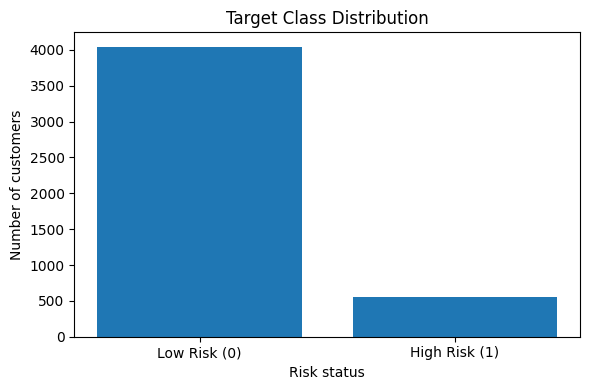

High-risk customers make up 12.11% of the dataset.
Interpretation: the target is imbalanced, so accuracy alone could give a misleading impression.


In [4]:
target_counts = df["risk_status"].value_counts().sort_index()
target_percent = (df["risk_status"].value_counts(normalize=True).sort_index() * 100)

plt.figure(figsize=(6,4))
plt.bar(["Low Risk (0)", "High Risk (1)"], [target_counts.get(0,0), target_counts.get(1,0)])
plt.title("Target Class Distribution")
plt.ylabel("Number of customers")
plt.xlabel("Risk status")
plt.tight_layout()
plt.show()

print(f"High-risk customers make up {target_percent.get(1,0):.2f}% of the dataset.")
print("Interpretation: the target is imbalanced, so accuracy alone could give a misleading impression.")

### Prepare features and target

We create `last_transaction_month` and `last_transaction_day`, then remove the raw date and customer ID. We use a stratified 80/20 split so that the low-risk/high-risk proportions remain similar in training and testing.

Missing numeric values will be handled with **KNN Imputer**. Missing categorical values will be filled using the most frequent category. Imputers are fitted on the training data only.

In [5]:
data = df.copy()

date_values = pd.to_datetime(data["last_transaction_date"], errors="coerce")
data["last_transaction_month"] = date_values.dt.month
data["last_transaction_day"] = date_values.dt.day
data = data.drop(columns=["customer_id", "last_transaction_date"])

X = data.drop(columns=["risk_status"])
y = data["risk_status"].astype(int)

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Training rows:", len(X_train_raw))
print("Testing rows:", len(X_test_raw))
print("\nTraining target proportion:")
display(y_train.value_counts(normalize=True).rename("proportion").to_frame())
print("Testing target proportion:")
display(y_test.value_counts(normalize=True).rename("proportion").to_frame())

Training rows: 3680
Testing rows: 920

Training target proportion:


,proportion
risk_status,
0,0.878804
1,0.121196


Testing target proportion:


,proportion
risk_status,
0,0.879348
1,0.120652


In [6]:
numeric_cols = X_train_raw.select_dtypes(include=["number"]).columns.tolist()
categorical_cols = X_train_raw.select_dtypes(exclude=["number"]).columns.tolist()

# Scale numeric columns before KNN imputation so large currency values do not dominate distances.
numeric_scaler = StandardScaler()
X_train_num_scaled = numeric_scaler.fit_transform(X_train_raw[numeric_cols])
X_test_num_scaled = numeric_scaler.transform(X_test_raw[numeric_cols])

knn_imputer = KNNImputer(n_neighbors=5)
X_train_num = pd.DataFrame(
    knn_imputer.fit_transform(X_train_num_scaled),
    columns=numeric_cols, index=X_train_raw.index
)
X_test_num = pd.DataFrame(
    knn_imputer.transform(X_test_num_scaled),
    columns=numeric_cols, index=X_test_raw.index
)

# Fill missing categories using the most common training category in each column.
X_train_cat = X_train_raw[categorical_cols].copy()
X_test_cat = X_test_raw[categorical_cols].copy()
for col in categorical_cols:
    most_common = X_train_cat[col].mode(dropna=True)
    fill_value = most_common.iloc[0] if len(most_common) else "Unknown"
    X_train_cat[col] = X_train_cat[col].fillna(fill_value)
    X_test_cat[col] = X_test_cat[col].fillna(fill_value)

# One-hot encode categories and align the test columns with training columns.
X_train_encoded = pd.concat([X_train_num, X_train_cat], axis=1)
X_test_encoded = pd.concat([X_test_num, X_test_cat], axis=1)
X_train_encoded = pd.get_dummies(X_train_encoded, columns=categorical_cols, dtype=int)
X_test_encoded = pd.get_dummies(X_test_encoded, columns=categorical_cols, dtype=int)
X_test_encoded = X_test_encoded.reindex(columns=X_train_encoded.columns, fill_value=0)

# Safety checks: no missing values should remain.
print("Missing values in prepared training data:", int(X_train_encoded.isna().sum().sum()))
print("Missing values in prepared test data:", int(X_test_encoded.isna().sum().sum()))
print("Prepared training shape:", X_train_encoded.shape)
print("Prepared test shape:", X_test_encoded.shape)

Missing values in prepared training data: 0
Missing values in prepared test data: 0
Prepared training shape: (3680, 28)
Prepared test shape: (920, 28)


**Interpretation:** the train/test split happened before fitting the numeric scaler and KNN imputer. The test set remains untouched by resampling. We also checked that no missing values remain after preparation.

## Part C — 📊 Baseline Logistic Regression

This is our starting point. We train on the original imbalanced training set, then evaluate on the untouched test set. The positive class (`1`) is the high-risk class.

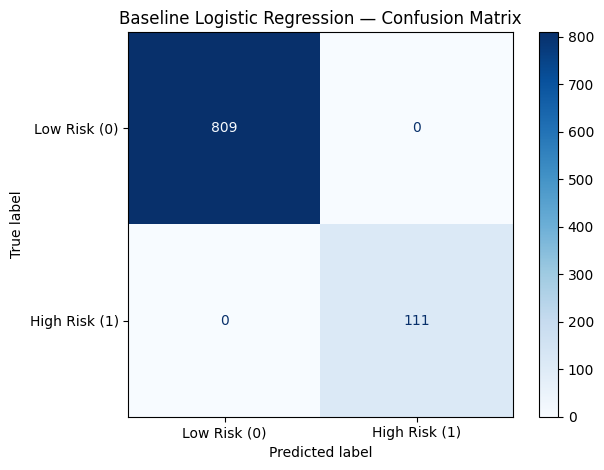

TN (correctly predicted low risk): 809
FP (low risk flagged as high risk / Type-I error): 0
FN (high risk missed / Type-II error): 0
TP (correctly identified high risk): 111

Accuracy: 1.0
Precision (high-risk class): 1.0
Recall (high-risk class): 1.0
F1-score (high-risk class): 1.0
ROC-AUC: 1.0

Classification report:
              precision    recall  f1-score   support

    Low Risk       1.00      1.00      1.00       809
   High Risk       1.00      1.00      1.00       111

    accuracy                           1.00       920
   macro avg       1.00      1.00      1.00       920
weighted avg       1.00      1.00      1.00       920



In [7]:
baseline_model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
baseline_model.fit(X_train_encoded, y_train)

baseline_pred = baseline_model.predict(X_test_encoded)
baseline_prob = baseline_model.predict_proba(X_test_encoded)[:, 1]

baseline_cm = confusion_matrix(y_test, baseline_pred, labels=[0, 1])
ConfusionMatrixDisplay(confusion_matrix=baseline_cm, display_labels=["Low Risk (0)", "High Risk (1)"]).plot(cmap="Blues")
plt.title("Baseline Logistic Regression — Confusion Matrix")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = baseline_cm.ravel()
print("TN (correctly predicted low risk):", tn)
print("FP (low risk flagged as high risk / Type-I error):", fp)
print("FN (high risk missed / Type-II error):", fn)
print("TP (correctly identified high risk):", tp)
print("\nAccuracy:", round(accuracy_score(y_test, baseline_pred), 4))
print("Precision (high-risk class):", round(precision_score(y_test, baseline_pred, zero_division=0), 4))
print("Recall (high-risk class):", round(recall_score(y_test, baseline_pred, zero_division=0), 4))
print("F1-score (high-risk class):", round(f1_score(y_test, baseline_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, baseline_prob), 4))
print("\nClassification report:")
print(classification_report(y_test, baseline_pred, target_names=["Low Risk", "High Risk"], zero_division=0))

**How to interpret the confusion matrix:** the top-left and bottom-right cells are correct predictions. **False positives** are low-risk customers flagged for review; **false negatives** are high-risk customers the bank fails to flag. Since the project asks us to minimize false negatives, high-risk recall is a key decision metric.

## Part D — ⚖️ Handle class imbalance

We will retrain Logistic Regression using four methods:

- **Under-sampling:** removes some majority-class examples.
- **Over-sampling:** repeats minority-class examples.
- **SMOTE:** creates synthetic minority-class examples.
- **ADASYN:** creates synthetic examples with more attention to difficult minority examples.

Resampling is applied to the **training data only**. The same untouched test set is used for every comparison.

In [8]:
samplers = {
    "Under-sampling": RandomUnderSampler(random_state=RANDOM_STATE),
    "Over-sampling": RandomOverSampler(random_state=RANDOM_STATE),
    "SMOTE": SMOTE(random_state=RANDOM_STATE),
    "ADASYN": ADASYN(random_state=RANDOM_STATE, n_neighbors=5)
}

imbalance_results = []
imbalance_models = {"Baseline (no resampling)": baseline_model}
for name, sampler in samplers.items():
    try:
        X_resampled, y_resampled = sampler.fit_resample(X_train_encoded, y_train)
        model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
        model.fit(X_resampled, y_resampled)
        pred = model.predict(X_test_encoded)
        prob = model.predict_proba(X_test_encoded)[:, 1]
        imbalance_models[name] = model
        imbalance_results.append({
            "Model": name,
            "Training rows after sampling": len(y_resampled),
            "High-risk recall": recall_score(y_test, pred, zero_division=0),
            "F1-score": f1_score(y_test, pred, zero_division=0),
            "ROC-AUC": roc_auc_score(y_test, prob),
            "Accuracy": accuracy_score(y_test, pred)
        })
    except Exception as e:
        print(f"{name} could not run: {e}")

baseline_result = {
    "Model": "Baseline (no resampling)",
    "Training rows after sampling": len(y_train),
    "High-risk recall": recall_score(y_test, baseline_pred, zero_division=0),
    "F1-score": f1_score(y_test, baseline_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, baseline_prob),
    "Accuracy": accuracy_score(y_test, baseline_pred)
}
imbalance_table = pd.DataFrame([baseline_result] + imbalance_results).sort_values("High-risk recall", ascending=False)
display(imbalance_table.round(4))

,Model,Training rows after sampling,High-risk recall,F1-score,ROC-AUC,Accuracy
0,Baseline (no resampling),3680,1.0,1.0000,1.0,1.0000
1,Under-sampling,892,1.0,0.9911,1.0,0.9978
2,Over-sampling,6468,1.0,0.9911,1.0,0.9978
3,SMOTE,6468,1.0,0.9911,1.0,0.9978
4,ADASYN,6481,1.0,0.9911,1.0,0.9978


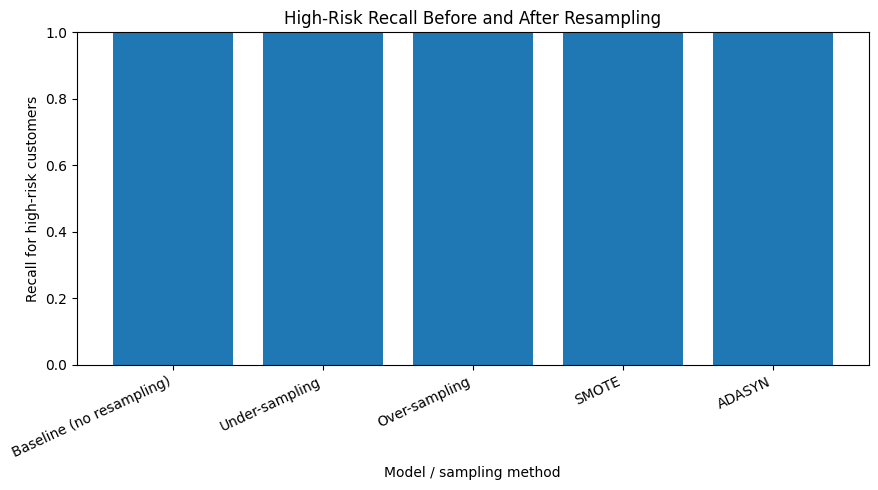

Interpretation: compare high-risk recall with F1-score and ROC-AUC together.
A higher recall means fewer risky customers are missed, but it may also create more false alarms.


In [9]:
plt.figure(figsize=(9,5))
plt.bar(imbalance_table["Model"], imbalance_table["High-risk recall"])
plt.title("High-Risk Recall Before and After Resampling")
plt.ylabel("Recall for high-risk customers")
plt.xlabel("Model / sampling method")
plt.xticks(rotation=25, ha="right")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

print("Interpretation: compare high-risk recall with F1-score and ROC-AUC together.")
print("A higher recall means fewer risky customers are missed, but it may also create more false alarms.")

## Part E — 🌳 Decision Tree and Random Forest

A Decision Tree makes decisions using a sequence of rules. It can overfit if it learns the training examples too closely. Random Forest combines many decision trees, which often improves generalization.

In [10]:
decision_tree = DecisionTreeClassifier(random_state=RANDOM_STATE)
decision_tree.fit(X_train_encoded, y_train)
dt_train_pred = decision_tree.predict(X_train_encoded)
dt_test_pred = decision_tree.predict(X_test_encoded)
dt_test_prob = decision_tree.predict_proba(X_test_encoded)[:, 1]

random_forest = RandomForestClassifier(n_estimators=60, random_state=RANDOM_STATE, n_jobs=1)
random_forest.fit(X_train_encoded, y_train)
rf_train_pred = random_forest.predict(X_train_encoded)
rf_test_pred = random_forest.predict(X_test_encoded)
rf_test_prob = random_forest.predict_proba(X_test_encoded)[:, 1]

tree_results = pd.DataFrame([
    {"Model":"Decision Tree", "Train accuracy":accuracy_score(y_train, dt_train_pred),
     "Test accuracy":accuracy_score(y_test, dt_test_pred),
     "High-risk recall":recall_score(y_test, dt_test_pred, zero_division=0),
     "F1-score":f1_score(y_test, dt_test_pred, zero_division=0),
     "ROC-AUC":roc_auc_score(y_test, dt_test_prob)},
    {"Model":"Random Forest", "Train accuracy":accuracy_score(y_train, rf_train_pred),
     "Test accuracy":accuracy_score(y_test, rf_test_pred),
     "High-risk recall":recall_score(y_test, rf_test_pred, zero_division=0),
     "F1-score":f1_score(y_test, rf_test_pred, zero_division=0),
     "ROC-AUC":roc_auc_score(y_test, rf_test_prob)}
])
display(tree_results.round(4))

,Model,Train accuracy,Test accuracy,High-risk recall,F1-score,ROC-AUC
0,Decision Tree,1.0,0.9761,0.8559,0.8962,0.9242
1,Random Forest,1.0,0.9989,0.9910,0.9955,0.9999


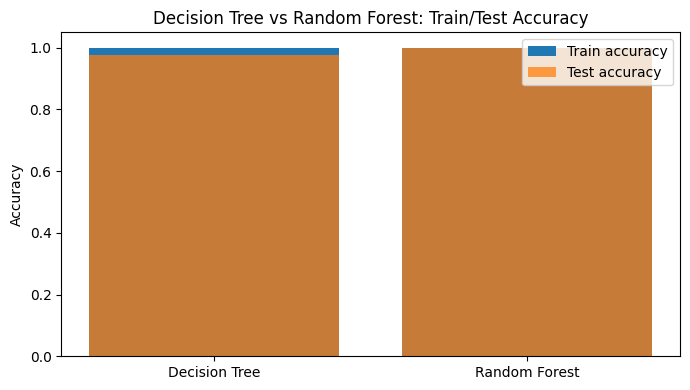

Interpretation: a large gap between training and test accuracy can indicate overfitting.
Prefer a model that generalizes well and finds high-risk customers, not simply one with perfect training accuracy.


In [11]:
plt.figure(figsize=(7,4))
plt.bar(tree_results["Model"], tree_results["Train accuracy"], label="Train accuracy")
plt.bar(tree_results["Model"], tree_results["Test accuracy"], label="Test accuracy", alpha=0.75)
plt.title("Decision Tree vs Random Forest: Train/Test Accuracy")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.legend()
plt.tight_layout()
plt.show()

print("Interpretation: a large gap between training and test accuracy can indicate overfitting.")
print("Prefer a model that generalizes well and finds high-risk customers, not simply one with perfect training accuracy.")

## Part F — 🔧 Hyperparameter tuning

We use **RandomizedSearchCV** to explore a limited set of Decision Tree and Random Forest settings. We optimize `recall` because the bank wants to reduce missed high-risk customers. Then we use a small **GridSearchCV** to fine-tune the model family with the stronger cross-validation recall.

For speed in this three-hour project, the searches use 3-fold cross-validation and a small search space. The test set is not used to choose hyperparameters.

In [12]:
dt_params = {
    "max_depth": [3, 5, 8, 12, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 5],
    "class_weight": [None, "balanced"]
}
rf_params = {
    "n_estimators": [40, 60, 80],
    "max_depth": [None, 8, 12, 18],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "class_weight": [None, "balanced", "balanced_subsample"]
}

dt_search = RandomizedSearchCV(
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    param_distributions=dt_params, n_iter=4, scoring="recall",
    cv=2, random_state=RANDOM_STATE, n_jobs=1
)
rf_search = RandomizedSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
    param_distributions=rf_params, n_iter=4, scoring="recall",
    cv=2, random_state=RANDOM_STATE, n_jobs=1
)

dt_search.fit(X_train_encoded, y_train)
rf_search.fit(X_train_encoded, y_train)

print("Decision Tree best CV recall:", round(dt_search.best_score_, 4))
print("Decision Tree best parameters:", dt_search.best_params_)
print("\nRandom Forest best CV recall:", round(rf_search.best_score_, 4))
print("Random Forest best parameters:", rf_search.best_params_)

Decision Tree best CV recall: 0.9103
Decision Tree best parameters: {'min_samples_split': 5, 'min_samples_leaf': 5, 'max_depth': 8, 'class_weight': 'balanced'}

Random Forest best CV recall: 0.9529
Random Forest best parameters: {'n_estimators': 40, 'min_samples_split': 10, 'min_samples_leaf': 4, 'max_depth': None, 'class_weight': 'balanced'}


In [13]:
# Select the model family using training-only cross-validation results.
if rf_search.best_score_ >= dt_search.best_score_:
    selected_family = "Random Forest"
    selected_estimator = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)
    selected_params = rf_search.best_params_
    grid_params = {
        "n_estimators": sorted(set([max(60, selected_params.get("n_estimators", 120)-40),
                                    selected_params.get("n_estimators", 120),
                                    selected_params.get("n_estimators", 120)+40])),
        "max_depth": [selected_params.get("max_depth", None)],
        "min_samples_split": [selected_params.get("min_samples_split", 2)],
        "min_samples_leaf": [selected_params.get("min_samples_leaf", 1)],
        "class_weight": [selected_params.get("class_weight", None)]
    }
else:
    selected_family = "Decision Tree"
    selected_estimator = DecisionTreeClassifier(random_state=RANDOM_STATE)
    selected_params = dt_search.best_params_
    grid_params = {
        "max_depth": [selected_params.get("max_depth", None)],
        "min_samples_split": [selected_params.get("min_samples_split", 2)],
        "min_samples_leaf": sorted(set([1, selected_params.get("min_samples_leaf", 1), 3])),
        "class_weight": [selected_params.get("class_weight", None)]
    }

print("Model family selected from CV:", selected_family)
print("Small fine-tuning grid:", grid_params)

grid_search = GridSearchCV(
    selected_estimator, param_grid=grid_params, scoring="recall",
    cv=2, n_jobs=1
)
grid_search.fit(X_train_encoded, y_train)
tuned_model = grid_search.best_estimator_
print("\nGridSearchCV best CV recall:", round(grid_search.best_score_, 4))
print("GridSearchCV best parameters:", grid_search.best_params_)

Model family selected from CV: Random Forest
Small fine-tuning grid: {'n_estimators': [40, 60, 80], 'max_depth': [None], 'min_samples_split': [10], 'min_samples_leaf': [4], 'class_weight': ['balanced']}

GridSearchCV best CV recall: 0.9641
GridSearchCV best parameters: {'class_weight': 'balanced', 'max_depth': None, 'min_samples_leaf': 4, 'min_samples_split': 10, 'n_estimators': 60}


### Tuned vs untuned performance

We now evaluate the tuned model on the same test set as the untuned tree models. These test metrics are for final comparison; cross-validation on the training data was used for tuning.

In [14]:
tuned_pred = tuned_model.predict(X_test_encoded)
tuned_prob = tuned_model.predict_proba(X_test_encoded)[:, 1]

tuning_comparison = pd.DataFrame([
    {"Model":"Untuned Decision Tree", "Accuracy":accuracy_score(y_test, dt_test_pred),
     "High-risk recall":recall_score(y_test, dt_test_pred, zero_division=0),
     "F1-score":f1_score(y_test, dt_test_pred, zero_division=0),
     "ROC-AUC":roc_auc_score(y_test, dt_test_prob)},
    {"Model":"Untuned Random Forest", "Accuracy":accuracy_score(y_test, rf_test_pred),
     "High-risk recall":recall_score(y_test, rf_test_pred, zero_division=0),
     "F1-score":f1_score(y_test, rf_test_pred, zero_division=0),
     "ROC-AUC":roc_auc_score(y_test, rf_test_prob)},
    {"Model":"Tuned " + selected_family, "Accuracy":accuracy_score(y_test, tuned_pred),
     "High-risk recall":recall_score(y_test, tuned_pred, zero_division=0),
     "F1-score":f1_score(y_test, tuned_pred, zero_division=0),
     "ROC-AUC":roc_auc_score(y_test, tuned_prob)}
])
display(tuning_comparison.round(4))

,Model,Accuracy,High-risk recall,F1-score,ROC-AUC
0,Untuned Decision Tree,0.9761,0.8559,0.8962,0.9242
1,Untuned Random Forest,0.9989,0.9910,0.9955,0.9999
2,Tuned Random Forest,0.9967,1.0000,0.9867,0.9999


## Part G — 📈 ROC curve and final model comparison

The ROC curve shows the trade-off between finding high-risk customers (TPR/recall) and incorrectly flagging low-risk customers (FPR). We compare probability scores for baseline Logistic Regression, all resampling models, both tree models and the tuned model.

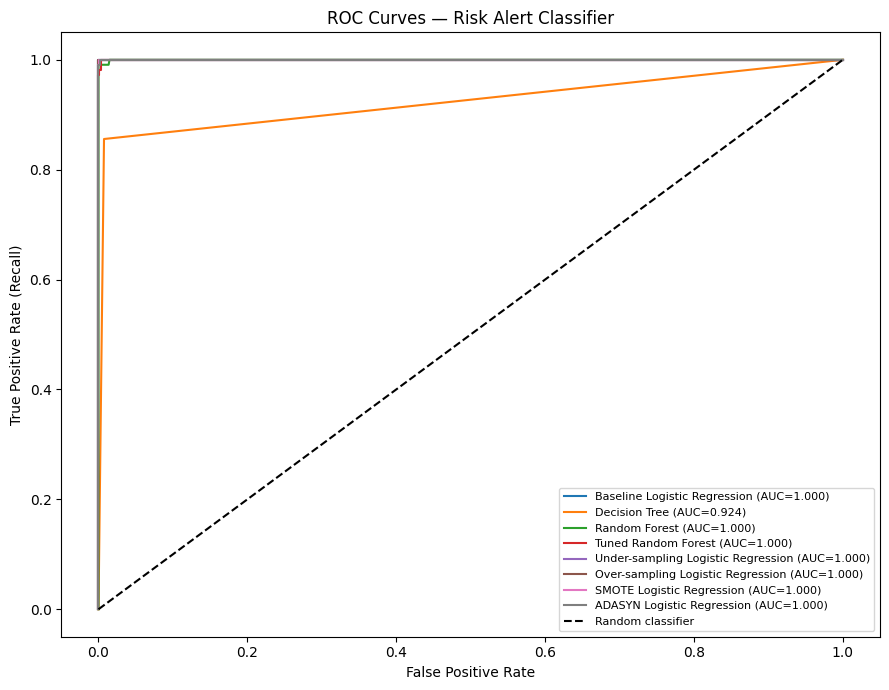

Interpretation: curves closer to the top-left generally indicate a stronger separation between low-risk and high-risk customers.


In [15]:
roc_models = {
    "Baseline Logistic Regression": (baseline_model, baseline_prob),
    "Decision Tree": (decision_tree, dt_test_prob),
    "Random Forest": (random_forest, rf_test_prob),
    "Tuned " + selected_family: (tuned_model, tuned_prob)
}
for name, model in imbalance_models.items():
    if name != "Baseline (no resampling)":
        roc_models[name + " Logistic Regression"] = (model, model.predict_proba(X_test_encoded)[:, 1])

plt.figure(figsize=(9,7))
for name, (model, prob) in roc_models.items():
    fpr, tpr, thresholds = roc_curve(y_test, prob)
    auc_value = roc_auc_score(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc_value:.3f})")
plt.plot([0,1], [0,1], "k--", label="Random classifier")
plt.title("ROC Curves — Risk Alert Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

print("Interpretation: curves closer to the top-left generally indicate a stronger separation between low-risk and high-risk customers.")

In [16]:
all_model_rows = []
for name, (model, prob) in roc_models.items():
    pred = model.predict(X_test_encoded)
    cm = confusion_matrix(y_test, pred, labels=[0,1])
    tn, fp, fn, tp = cm.ravel()
    all_model_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "High-risk Recall": recall_score(y_test, pred, zero_division=0),
        "F1-score": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, prob),
        "False Negatives": fn,
        "False Positives": fp
    })

final_comparison = pd.DataFrame(all_model_rows).sort_values(
    ["High-risk Recall", "F1-score", "ROC-AUC"], ascending=False
).reset_index(drop=True)
display(final_comparison.round(4))

,Model,Accuracy,Precision,High-risk Recall,F1-score,ROC-AUC,False Negatives,False Positives
0,Baseline Logistic Regression,1.0000,1.0000,1.0000,1.0000,1.0000,0,0
1,Under-sampling Logistic Regression,0.9978,0.9823,1.0000,0.9911,1.0000,0,2
2,Over-sampling Logistic Regression,0.9978,0.9823,1.0000,0.9911,1.0000,0,2
3,SMOTE Logistic Regression,0.9978,0.9823,1.0000,0.9911,1.0000,0,2
4,ADASYN Logistic Regression,0.9978,0.9823,1.0000,0.9911,1.0000,0,2
5,Tuned Random Forest,0.9967,0.9737,1.0000,0.9867,0.9999,0,3
6,Random Forest,0.9989,1.0000,0.9910,0.9955,0.9999,1,0
7,Decision Tree,0.9761,0.9406,0.8559,0.8962,0.9242,16,6


### Choose a model for the business

The project specifically says to minimize false negatives. Therefore, we first compare high-risk recall (higher is better), then F1-score and ROC-AUC to help balance finding risky customers with avoiding too many false alarms. This is a business-oriented selection rule, not a claim that one metric is always best for every bank.

In [17]:
best_row = final_comparison.iloc[0]
best_model_name = best_row["Model"]
print("Recommended model using the stated priority:", best_model_name)
print(f"High-risk recall: {best_row['High-risk Recall']:.3f}")
print(f"F1-score: {best_row['F1-score']:.3f}")
print(f"ROC-AUC: {best_row['ROC-AUC']:.3f}")
print(f"False negatives: {int(best_row['False Negatives'])}")
print(f"False positives: {int(best_row['False Positives'])}")

print("\nBusiness meaning:")
print("- A false negative is a high-risk customer the model failed to alert the bank about.")
print("- A false positive is a low-risk customer sent for an unnecessary review.")
print("- The final decision should consider the cost of missed risk and the review capacity of the bank.")

Recommended model using the stated priority: Baseline Logistic Regression
High-risk recall: 1.000
F1-score: 1.000
ROC-AUC: 1.000
False negatives: 0
False positives: 0

Business meaning:
- A false negative is a high-risk customer the model failed to alert the bank about.
- A false positive is a low-risk customer sent for an unnecessary review.
- The final decision should consider the cost of missed risk and the review capacity of the bank.


### 🔍 Important model-quality check

The baseline may produce exceptionally high scores on this dataset. A perfect score is not proof that the model will be perfect in real life. It can happen when a supplied dataset was generated using consistent rules, but it should always trigger a careful check for target leakage, duplicated records, and whether the test set represents future customers. This notebook excludes the customer ID and target from the input features, uses a stratified holdout set, and fits preprocessing only on training data. For real deployment, test on a later time period and validate with the bank’s domain experts.

In [18]:
# Save the chosen model and preprocessing objects so the Streamlit app can reuse them.
import joblib

chosen_model = roc_models[best_model_name][0]
artifact = {
    "model": chosen_model,
    "numeric_cols": numeric_cols,
    "categorical_cols": categorical_cols,
    "numeric_scaler": numeric_scaler,
    "knn_imputer": knn_imputer,
    "category_fill_values": {
        col: (X_train_raw[col].mode(dropna=True).iloc[0] if len(X_train_raw[col].mode(dropna=True)) else "Unknown")
        for col in categorical_cols
    },
    "encoded_columns": X_train_encoded.columns.tolist(),
    "model_name": best_model_name,
    "expected_raw_columns": X.columns.tolist()
}
joblib.dump(artifact, "risk_alert_model.joblib")
print("Saved model artifact: risk_alert_model.joblib ✅")
print("Model saved:", best_model_name)

Saved model artifact: risk_alert_model.joblib ✅
Model saved: Baseline Logistic Regression


## Part H — 🧾 Final analysis and report

### Conclusion template (based on the results printed above)

This project developed a Risk Alert Classifier using Logistic Regression, Decision Tree and Random Forest. Missing numeric data was handled with KNN Imputer, categorical missing values were filled using the most frequent training value, and the training/test split preserved the target distribution.

Four imbalance-handling methods were tested: under-sampling, over-sampling, SMOTE and ADASYN. Their impact was compared using high-risk recall, F1-score, ROC-AUC and accuracy. Decision Tree and Random Forest were compared for training versus test accuracy, and RandomizedSearchCV followed by GridSearchCV was used to tune model parameters.

The recommended model is the one selected in the final comparison table, prioritizing high-risk recall to reduce false negatives. False positives can create extra manual reviews, while false negatives can allow risky accounts to go unnoticed. A real bank should validate the model on newer data, check fairness and data privacy, and select a probability threshold based on business costs before deployment.

**Before submitting:** replace this template with one or two sentences that quote your actual best model and metrics from the notebook outputs. Do not claim a method improved performance unless your results table shows that it did.


---

# 📚 References & Acknowledgements

This project was completed as part of the Supervised Learning practical examination. The following sources supported the dataset selection, machine-learning implementation, technical explanations and project development.


## 1. Course and Assessment Material

2. Red & White Skill Education. (n.d.). *Practical Exam — Supervised Learning Set B* [Course assessment handout].

   This document provided the project requirements, learning objectives, required algorithms, evaluation metrics, preprocessing tasks and submission criteria.

## 2. Python Libraries and Technical Documentation

3. The pandas development team. (n.d.). *pandas documentation*. https://pandas.pydata.org/docs/

   Reference for data loading, cleaning, missing-value handling, grouping and tabular analysis.

4. NumPy developers. (n.d.). *NumPy documentation*. https://numpy.org/doc/

   Reference for numerical operations and array-based calculations.

5. scikit-learn developers. (n.d.). *scikit-learn documentation*. https://scikit-learn.org/stable/

   Reference for train-test splitting, feature scaling, classification algorithms, cross-validation, evaluation metrics, confusion matrices, ROC curves, pipelines and model persistence workflows.

6. Matplotlib development team. (n.d.). *Matplotlib documentation*. https://matplotlib.org/stable/

   Reference for creating and formatting charts and visualizations.

7. seaborn development team. (n.d.). *seaborn documentation*. https://seaborn.pydata.org/

   Reference for statistical visualizations, including count plots, boxplots, heatmaps and model-comparison charts.

8. The imbalanced-learn developers. (n.d.). *imbalanced-learn documentation*. https://imbalanced-learn.org/stable/

   Reference for handling class imbalance with SMOTE and using resampling within a machine-learning pipeline.

9. Joblib developers. (n.d.). *joblib documentation*. https://joblib.readthedocs.io/en/stable/

   Reference for saving and loading the trained machine-learning pipeline.

## 3. AI Assistance and Acknowledgement

10. OpenAI. (2026). *ChatGPT (GPT-6)* [Large language model]. https://chatgpt.com/

    ChatGPT was used as an AI-assisted learning and development tool to help explain machine-learning concepts, troubleshoot Python errors, improve notebook organization, refine code and strengthen the clarity of business interpretations. The AI assistance supported the development process; the dataset, code execution, experimental results and final submission should be reviewed and understood by the student.

## 4. Academic Integrity Statement

The dataset and technical resources listed above are acknowledged for their contributions to this project. Explanations and interpretations have been written to communicate the project's methods and findings in my own project context.

The reported metrics and business conclusions should be based on the actual execution of the notebook. Any adapted code, external material or AI-assisted content should be disclosed in accordance with the institute's academic integrity and AI-use policies.

---
